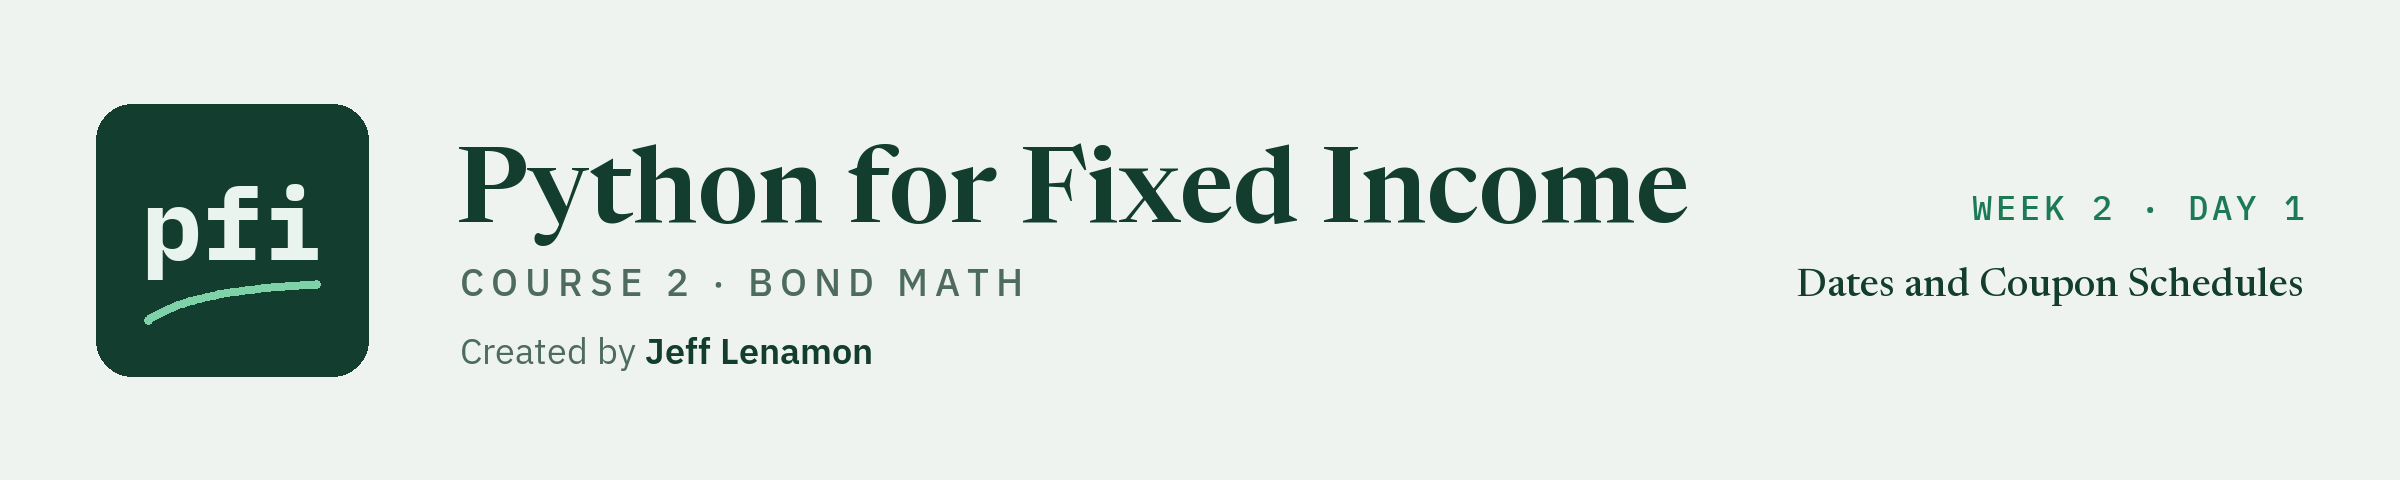

# Dates and Coupon Schedules

Week 2, Day 1. Bonds now settle between coupons: dates in Python, moving a date by months, and a coupon schedule counted back from maturity, tied to Excel's `COUPPCD`, `COUPNCD`, and `COUPNUM`.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week2/day1/06_dates_and_coupon_schedules.ipynb)

### The Desk Lead's Note

> Week 2 moves our four bonds off the coupon date: they settle Monday 30 November 2026. Before anyone prices them, I need three facts per bond: the previous coupon, the next coupon, and how many are left, each tied to Excel. Put the date logic in `bondmath`, with tests. Then the holdings file: which bonds pay a coupon before year end, and how much cash is that? Last, two benchmark bonds will not tie to Excel: tell me why.

![Quorvane's life from issue on 30 September 2026 to maturity on 30 September 2031, with a tick every six months and no dates on the ticks. Settlement, 30 November 2026, sits just after the first tick. Three arrows ask the questions: the previous coupon, the tick before settlement; the next coupon, the tick after it; and coupons left, a bracket over every tick after settlement](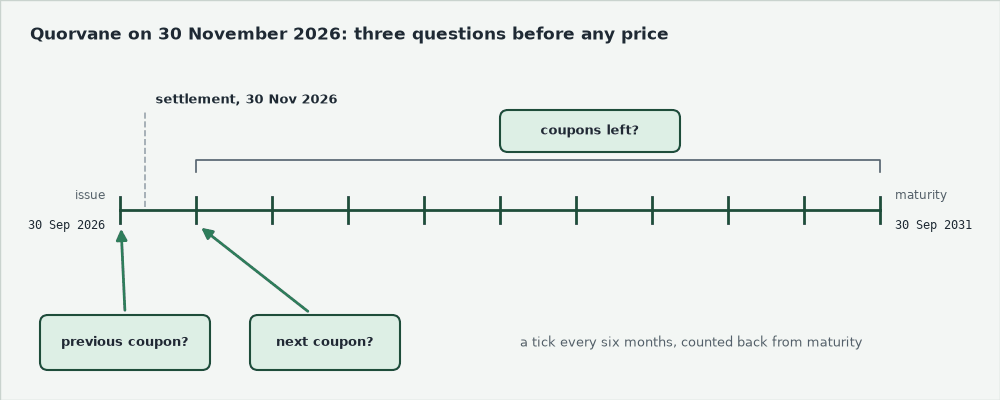)

Interest accrues from the previous coupon, so every price this week starts from these three answers.

**Week 1 lived on a coupon date; today the coupon dates must be found.**

### Today's Work Folder, and Its Tests

Q. Set up the day: how many tests pass this morning?

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module, its tests, and its Git history
# as notebook 05 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(6)

Work folder pfi_course2_06_k4w7q2xr: 4 data files, the module as notebook 05 left it, 5 commits, tagged week1


In [2]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.............                                                            [100%]
13 passed in 0.50s



**The module starts the day as notebook 05 left it: six functions, 13 tests.**

### Imports

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])
# the module the setup copied into the work folder
import bondmath

### The Four Bonds

The issuers are invented; every statement describes the data.

In [4]:
# week 1's four bonds; the maturities typed as text, as a file holds them
bonds = pd.DataFrame({
    'cusip': ['99001BZA7', '99002CZA4', '99003DZA1', '99004EZA8'],
    'issuer': ['Quorvane Energy', 'Dunmarrow Rail', 'Pellwick Paper', 'Halvering Foods'],
    'ticker': ['QVNE', 'DNMR', 'PLWK', 'HLVF'],
    'coupon_pct': [5.25, 6.125, 4.75, 7.5],
    'maturity': ['2031-09-30', '2033-09-30', '2029-09-30', '2036-09-30'],
})
bonds

,cusip,issuer,ticker,coupon_pct,maturity
0,99001BZA7,Quorvane Energy,QVNE,5.250,2031-09-30
1,99002CZA4,Dunmarrow Rail,DNMR,6.125,2033-09-30
2,99003DZA1,Pellwick Paper,PLWK,4.750,2029-09-30
3,99004EZA8,Halvering Foods,HLVF,7.500,2036-09-30


## 6.1 Dates in Python

### Settlement and Issue

Q. How many days from issue to settlement, and what weekday is settlement?

In [5]:
# date is Course 1's Day 0; timedelta, a length of time, is new
from datetime import date, timedelta

issue = date(2026, 9, 30)
settlement = date(2026, 11, 30)
# one date minus another is a timedelta; .days is its length in whole days
print('Issue to settlement:', (settlement - issue).days, 'days')
# .year, .month and .day are whole numbers; strftime('%A') writes the weekday's name
print(settlement.year, settlement.month, settlement.day, settlement.strftime('%A'))

Issue to settlement: 61 days
2026 11 30 Monday


The 31 days of October and the 30 of November.
The course does not move dates for weekends or holidays.

### Later, Earlier, From Text

Q. What is the day after settlement, and which comes first, settlement or Quorvane's maturity?

In [6]:
# a date plus a timedelta is another date
print('The day after:', settlement + timedelta(days=1))
# date.fromisoformat reads year-month-day text into a date
quorvane_maturity = date.fromisoformat('2031-09-30')
# dates compare in calendar order: earlier is smaller
print(settlement < quorvane_maturity, max(settlement, quorvane_maturity))

The day after: 2026-12-01
True 2031-09-30


A `date` prints year-month-day, the ISO layout the course's files use.

### Every Maturity as a Date

The table's `'2031-09-30'` is ten characters of text, and Python cannot count days between two texts.

Q. Turn every maturity into a date, and check that each comes after settlement.

In [7]:
bonds['maturity_date'] = [date.fromisoformat(text) for text in bonds['maturity']]
# stop here if any bond matures on or before settlement
assert (bonds['maturity_date'] > settlement).all(), 'a bond matures before settlement'
print(bonds['maturity_date'].tolist())

[datetime.date(2031, 9, 30), datetime.date(2033, 9, 30), datetime.date(2029, 9, 30), datetime.date(2036, 9, 30)]


The `assert` stayed silent, and the column now holds `date` values that subtract and compare.

### What Excel Keeps Under a Date

Q. What number does Excel keep under 30 November 2026?

In [8]:
# Excel counts days from 30 December 1899, for every date from 1 March 1900 on
excel_serial = (settlement - date(1899, 12, 30)).days
print('Excel serial of', settlement, 'is', excel_serial)

Excel serial of 2026-11-30 is 46356


Type `=DATE(2026,11,30)` in Excel and set the cell's number format to General: it shows 46356.
Why 30 December 1899, and not the 31st?

> STORY: Excel counts 1 January 1900 as day 1 and treats 1900 as a leap year, which it was not: `=DATE(1900,2,29)` returns 60. Microsoft explains that Lotus 1-2-3 made the same assumption, and Excel kept it so worksheets could move between the two programs. That extra day is why the count in Python starts from 30 December 1899, not the 31st. Source: Microsoft Learn, "Excel incorrectly assumes that the year 1900 is a leap year", https://learn.microsoft.com/en-us/troubleshoot/microsoft-365-apps/excel/wrongly-assumes-1900-is-leap-year

### 29 February 1900

Q. Does Python agree that 29 February 1900 existed?

In [9]:
# 1900 divides by 100 and not by 400, so it was not a leap year
date(1900, 2, 29)

ValueError: day is out of range for month

A `date` refuses a day that does not exist.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Days between</td><td align="left"><code>(settlement - issue).days</code></td><td align="left"><code>=DATE(2026,11,30)-DATE(2026,9,30)</code></td><td align="left">61</td></tr>
<tr><td align="left">Weekday</td><td align="left"><code>settlement.strftime('%A')</code></td><td align="left"><code>=TEXT(DATE(2026,11,30),"dddd")</code></td><td align="left">Monday</td></tr>
<tr><td align="left">Year, month, day</td><td align="left"><code>settlement.year</code></td><td align="left"><code>=YEAR(DATE(2026,11,30))</code>, <code>MONTH</code>, <code>DAY</code></td><td align="left">2026, 11, 30</td></tr>
<tr><td align="left">A day later</td><td align="left"><code>settlement + timedelta(days=1)</code></td><td align="left"><code>=DATE(2026,11,30)+1</code></td><td align="left">46357, 1 December 2026</td></tr>
<tr><td align="left">Earlier, later</td><td align="left"><code>max(settlement, quorvane_maturity)</code></td><td align="left"><code>=MAX(DATE(2026,11,30),DATE(2031,9,30))</code></td><td align="left">48121, 30 September 2031</td></tr>
<tr><td align="left">Text to a date</td><td align="left"><code>date.fromisoformat('2031-09-30')</code></td><td align="left"><code>=DATEVALUE("2031-09-30")</code></td><td align="left">48121</td></tr>
</table>
<br clear="left">

Excel returns a date as its serial number; a date format shows it as a date.

**A `date` adds, subtracts, and compares; Excel's dates are day counts, so the two agree.**

## 6.2 Six Months Is Not 182 Days

A semiannual bond pays every six months, and half of 365 is about 182.

### Predict 1: Two Steps of 182 Days

**Predict 1**

The second coupon after issue falls on 30 September 2027.

Q. Step 182 days from issue, then 182 more. Where do you land?

A) 30 September 2027, on the coupon date
B) 29 September 2027, a day short
C) 1 October 2027, a day past

In [10]:
first = issue + timedelta(days=182)
print(issue, '+ 182 days =', first)
print(first, '+ 182 days =', first + timedelta(days=182))

2026-09-30 + 182 days = 2027-03-31
2027-03-31 + 182 days = 2027-09-29


B.
31 March to 30 September is 183 days, not 182.

### Predict 2: Ten Steps

**Predict 2**

The tenth coupon after issue is Quorvane's maturity, 30 September 2031.

Q. Ten steps of 182 days from issue: how many days short of maturity do you land? Write down a number.

In [11]:
tenth = issue + timedelta(days=182 * 10)
print(tenth, 'is', (quorvane_maturity - tenth).days, 'days short of', quorvane_maturity)

2031-09-24 is 6 days short of 2031-09-30


Six days, and 13 by the twentieth coupon: a fixed number of days drifts.

### How Long Is a Month?

Q. How long is each month, and how many days are in the six months that start in each month of 2027?

In [12]:
import calendar

# monthrange(year, month) gives two numbers: the weekday of the 1st, then the days in the month
month_days = []
for year in [2027, 2028]:
    for month in range(1, 13):
        month_days.append(calendar.monthrange(year, month)[1])
print('February 2027:', month_days[1], ' February 2028:', month_days[13])
# the six months that start in month i: six lengths added up
six_months = [sum(month_days[i:i + 6]) for i in range(12)]
print(six_months)

February 2027: 28  February 2028: 29
[181, 181, 184, 183, 184, 183, 184, 184, 182, 183, 182, 183]


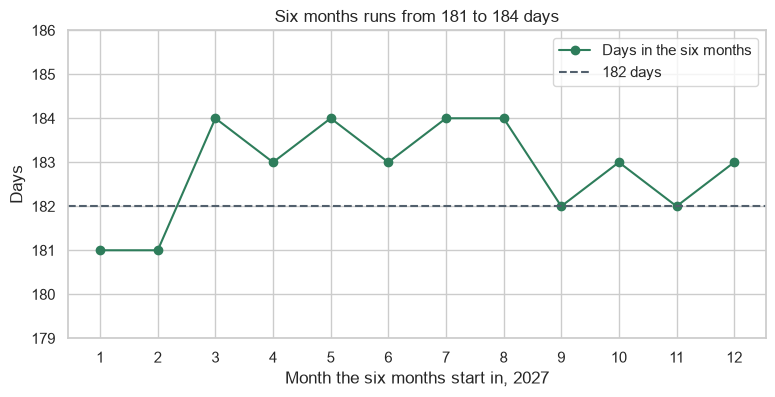

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, 13), six_months, marker='o', label='Days in the six months')
ax.axhline(182, color='#52606D', linestyle='--', label='182 days')
ax.set_ylim(179, 186)
ax.set_xticks(range(1, 13))
ax.set_title('Six months runs from 181 to 184 days')
ax.set_xlabel('Month the six months start in, 2027')
ax.set_ylabel('Days')
ax.legend()
plt.show()

### Month 15, and 31 February

Q. Then move the month number instead: six months after September is month 9 + 6.

In [14]:
date(2026, 9 + 6, 30)

ValueError: month must be in 1..12

Q. And 31 August moved six months on, into February?

In [15]:
date(2027, 2, 31)

ValueError: day is out of range for month

Past December the months must carry into the year, and in a short month the day must come down to its last day.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">182 days, twice</td><td align="left"><code>issue + timedelta(days=182)</code>, twice</td><td align="left"><code>=DATE(2026,9,30)+182+182</code></td><td align="left">46659, 29 September 2027</td></tr>
<tr><td align="left">Days in a month</td><td align="left"><code>calendar.monthrange(2027, 2)[1]</code></td><td align="left"><code>=DAY(EOMONTH(DATE(2027,2,1),0))</code></td><td align="left">28 (2028: 29)</td></tr>
</table>
<br clear="left">

`EOMONTH(date, 0)` is the last day of the date's month, so its `DAY` is the month's length.

**Moving by months must carry into the year and cut the day to a short month.**

## 6.3 `add_months`

### Months in One Long Count

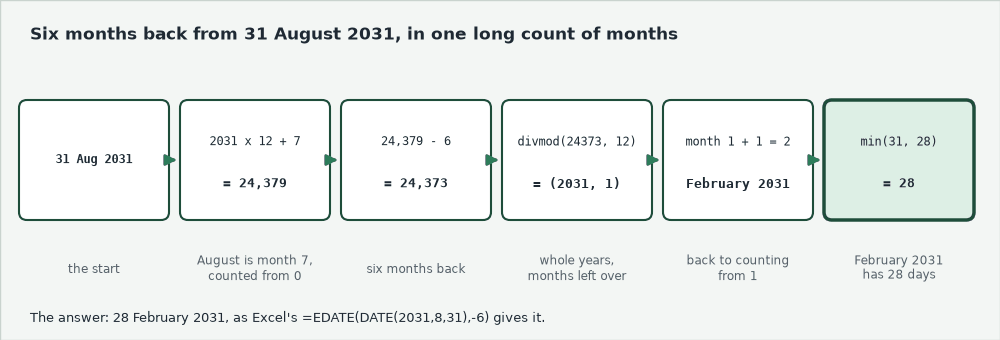

Number every month in one long count: the year times 12, plus the month counted from 0.
Add the months, then split the count back into a year and a month.

Q. Where do six months before 31 August 2031 land?

In [16]:
# August is month 7 counted from 0; six months back takes off 6
month_index = 2031 * 12 + (8 - 1) - 6
# divmod(a, b) gives a // b and a % b together: whole years, then months left over
year, month_zero_based = divmod(month_index, 12)
print(month_index, '->', year, month_zero_based + 1)

24373 -> 2031 2


**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Whole years</td><td align="left"><code>divmod(month_index, 12)[0]</code></td><td align="left"><code>=QUOTIENT(2031*12+7-6,12)</code></td><td align="left">2031</td></tr>
<tr><td align="left">Months left over</td><td align="left"><code>divmod(month_index, 12)[1]</code></td><td align="left"><code>=MOD(2031*12+7-6,12)</code></td><td align="left">1</td></tr>
</table>
<br clear="left">

### Append It, Docstring First

`add_months(d, months)` takes a date and a whole number of months, negative to move back.
Its docstring gives the units, the convention (the day cut to a short month's last day), and Excel's `EDATE`.

Q. Append `add_months` to `bondmath.py`.

In [17]:
%%writefile -a bondmath.py


import calendar
from datetime import date


def add_months(d: date, months: int) -> date:
    """Move a date by whole months, keeping the day of the month where the month allows it.

    Units: d is a date, months a whole number (negative moves back).
    Convention: the day is clamped to the length of the new month, so 31 August minus 6 months is
    28 February (29 February in a leap year). Excel: =EDATE(d, months)
    """
    # count months from year 0 so the year and month come out of one division
    month_index = d.year * 12 + (d.month - 1) + months
    year, month_zero_based = divmod(month_index, 12)
    month = month_zero_based + 1
    # the number of days in the new month
    days_in_month = calendar.monthrange(year, month)[1]
    # keep the day, or use the last day of a shorter month
    return date(year, month, min(d.day, days_in_month))

Appending to bondmath.py


`%%writefile -a` only adds to the end, so the two imports the function needs come in with it.

### Five Dates Against EDATE

Q. Reload the module and move five dates.

In [18]:
import importlib

# the file changed, so read it again
importlib.reload(bondmath)
cases = [(date(2031, 8, 31), -6), (date(2032, 8, 31), -6), (date(2027, 1, 31), 1),
         (date(2026, 11, 15), 3), (date(2031, 9, 30), -6)]
for d, months in cases:
    print(d, months, '->', bondmath.add_months(d, months))

2031-08-31 -6 -> 2031-02-28
2032-08-31 -6 -> 2032-02-29
2027-01-31 1 -> 2027-02-28
2026-11-15 3 -> 2027-02-15
2031-09-30 -6 -> 2031-03-30


**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Back into a short February</td><td align="left"><code>bondmath.add_months(date(2031, 8, 31), -6)</code></td><td align="left"><code>=EDATE(DATE(2031,8,31),-6)</code></td><td align="left">2031-02-28</td></tr>
<tr><td align="left">A leap February</td><td align="left"><code>bondmath.add_months(date(2032, 8, 31), -6)</code></td><td align="left"><code>=EDATE(DATE(2032,8,31),-6)</code></td><td align="left">2032-02-29</td></tr>
<tr><td align="left">One month on from a 31st</td><td align="left"><code>bondmath.add_months(date(2027, 1, 31), 1)</code></td><td align="left"><code>=EDATE(DATE(2027,1,31),1)</code></td><td align="left">2027-02-28</td></tr>
<tr><td align="left">Across a year end</td><td align="left"><code>bondmath.add_months(date(2026, 11, 15), 3)</code></td><td align="left"><code>=EDATE(DATE(2026,11,15),3)</code></td><td align="left">2027-02-15</td></tr>
<tr><td align="left">30 September back</td><td align="left"><code>bondmath.add_months(date(2031, 9, 30), -6)</code></td><td align="left"><code>=EDATE(DATE(2031,9,30),-6)</code></td><td align="left">2031-03-30</td></tr>
</table>
<br clear="left">

### The Test

Q. Pin `add_months` to four of Excel's `EDATE` values.

In [19]:
%%writefile -a test_bondmath.py


from datetime import date


def test_add_months_clamps_to_month_end():
    # 31 August back 6 months: 28 February, or 29 February in a leap year
    assert bondmath.add_months(date(2031, 8, 31), -6) == date(2031, 2, 28)
    assert bondmath.add_months(date(2032, 8, 31), -6) == date(2032, 2, 29)
    # 31 January forward 1 month
    assert bondmath.add_months(date(2027, 1, 31), 1) == date(2027, 2, 28)
    # a day every month has is kept, across a year end
    assert bondmath.add_months(date(2026, 11, 15), 3) == date(2027, 2, 15)

Appending to test_bondmath.py


In [20]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..............                                                           [100%]
14 passed in 0.50s



**`add_months` is Excel's `EDATE`, tested.**

## 6.4 Count Back From Maturity

A semiannual bond pays on maturity and every six months before it, so its schedule is counted back from maturity.

### Quorvane's Last Four Coupons

Q. Which are Quorvane's last four coupon dates?

In [21]:
# coupon k: maturity moved back k times 6 months
for k in range(4):
    print(k, bondmath.add_months(quorvane_maturity, -6 * k))

0 2031-09-30
1 2031-03-30
2 2030-09-30
3 2030-03-30


Each date is counted from maturity itself.
A shorter-looking loop steps from the date before: `add_months(previous, -6)`.

### Predict 3: Stepped or Counted

**Predict 3**

A bond matures on 30 August 2031.
February has no 30th, so the first date back is 28 February 2031 either way.

Q. Over the first four dates back, on how many do stepping and counting differ?

A) None
B) One, August 2030
C) Two, both Augusts

In [22]:
august_maturity = date(2031, 8, 30)
stepped = [august_maturity]
for k in range(4):
    # each date moved from the date before it: stepped[-1] is the last one added
    stepped.append(bondmath.add_months(stepped[-1], -6))
# each date moved from maturity itself
counted = [bondmath.add_months(august_maturity, -6 * k) for k in range(1, 5)]
pd.DataFrame({'stepped': stepped[1:], 'counted': counted})

,stepped,counted
0,2031-02-28,2031-02-28
1,2030-08-28,2030-08-30
2,2030-02-28,2030-02-28
3,2029-08-28,2029-08-30


![Two ladders down from maturity, 30 August 2031. Stepped: each arrow starts at the date before, so 28 February 2031 leads to 28 August 2030, 28 February 2030 and 28 August 2029. Counted: every arrow starts at maturity, giving 28 February 2031, 30 August 2030, 28 February 2030 and 30 August 2029](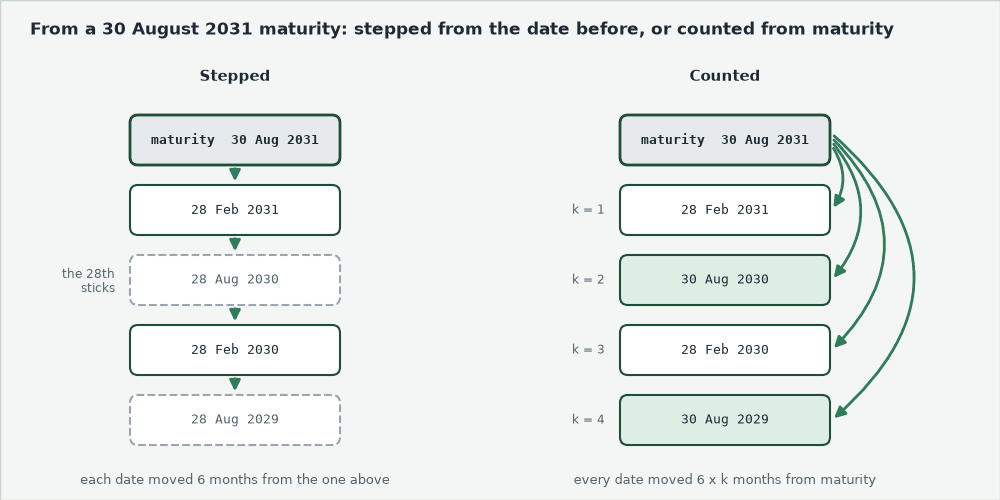)

C.
Once February cuts the 30th to the 28th, the 28th sticks for every date stepped after it.
Counted from maturity, each August is back on the 30th.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Stepped</td><td align="left"><code>bondmath.add_months(stepped[-1], -6)</code></td><td align="left">maturity in A1, <code>=EDATE(A1,-6)</code> in A2, filled down</td><td align="left">2031-02-28, 2030-08-28, 2030-02-28, 2029-08-28</td></tr>
<tr><td align="left">Counted</td><td align="left"><code>bondmath.add_months(august_maturity, -6 * k)</code></td><td align="left">1 to 4 in C2:C5, <code>=EDATE($A$1,-6*C2)</code> in B2, filled down</td><td align="left">2031-02-28, 2030-08-30, 2030-02-28, 2029-08-30</td></tr>
</table>
<br clear="left">

The `$` signs hold A1 fixed as the formula fills down.

**Count every coupon date from maturity, never from the date before.**

## 6.5 The Month-End Rule

Counted from maturity, Quorvane's March coupons fall on 30 March.

### Predict 4: What Does Excel Say?

**Predict 4**

Two bonds: Quorvane, maturing 30 September 2031, and a bond in Excel's reference file maturing 30 March 2031, settled 15 October 2026.
Counted from maturity, both next coupons fall on 30 March 2027.

Q. What does Excel's `COUPNCD` say?

A) Quorvane moves to 31 March 2027; the other bond stays on the 30th
B) Both move to 31 March 2027
C) Neither moves

In [23]:
# Excel's answer key, one row per case, labelled by case_id; Quorvane's is its CUSIP
reference = pd.read_csv('bondmath_excel_reference.csv', index_col='case_id')
print('Quorvane       Excel', reference.loc['99001BZA7', 'coupncd'],
      ' counted', bondmath.add_months(quorvane_maturity, -6 * 9))
print('30 March bond  Excel', reference.loc['edge_mat_30_mar', 'coupncd'],
      ' counted', bondmath.add_months(date(2031, 3, 30), -6 * 8))

Quorvane       Excel 2027-03-31  counted 2027-03-30
30 March bond  Excel 2027-03-30  counted 2027-03-30


![Two bonds' coupon dates in a row each. Quorvane matures on 30 September, the last day of September, so every coupon goes to the last day of its month: 31 March, 30 September, 31 March. The bond maturing on 30 March, not the last day of March, keeps the 30th: 30 September, 30 March](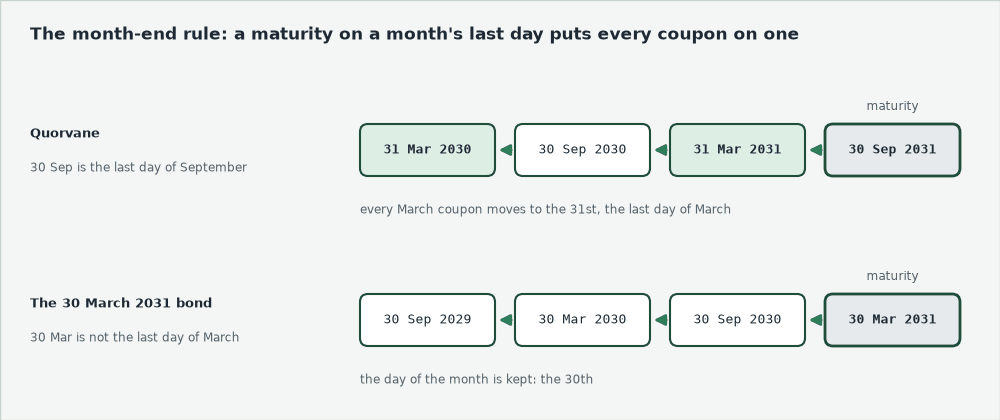)

A.
Quorvane matures on the last day of September, so Excel puts every coupon on the last day of its month.
This is the **month-end rule**.
Any other maturity keeps its day, cut to a short month's last day, as `add_months` does.
The rule holds on all 306 reference rows and on 2,508 more cases tested in Excel for the course.

### Is It a Month End?

Q. Is each date the last day of its month?

In [24]:
for d in [quorvane_maturity, august_maturity, date(2031, 2, 28), date(2032, 2, 28)]:
    # the last day: the day equals the number of days in that month
    print(d, d.day == calendar.monthrange(d.year, d.month)[1])

2031-09-30 True
2031-08-30 False
2031-02-28 True
2032-02-28 False


`EOMONTH(date, months)` moves a date by whole months and returns that month's last day.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">A month end, then not</td><td align="left"><code>d.day == calendar.monthrange(d.year, d.month)[1]</code></td><td align="left"><code>=DATE(2031,9,30)=EOMONTH(DATE(2031,9,30),0)</code>, then <code>DATE(2031,8,30)</code></td><td align="left">TRUE, then FALSE</td></tr>
<tr><td align="left">February, two years</td><td align="left">the same, 28 February 2031 and 2032</td><td align="left"><code>=DATE(2031,2,28)=EOMONTH(DATE(2031,2,28),0)</code>, then 2032</td><td align="left">TRUE, then FALSE</td></tr>
<tr><td align="left">Back to month ends</td><td align="left"><code>add_months</code>, then the day set to <code>calendar.monthrange(...)[1]</code></td><td align="left"><code>=EOMONTH(DATE(2031,9,30),-6)</code>, then <code>-12</code></td><td align="left">2031-03-31, 2030-09-30</td></tr>
</table>
<br clear="left">

### Append `coupon_dates`

`coupon_dates(settlement, maturity, frequency=2)` returns the previous coupon, then every coupon left through maturity, earliest first.
So `[0]` is Excel's `COUPPCD`, `[1]` is `COUPNCD`, and `len - 1` is `COUPNUM`.
It loops with `while True`, which never stops on its own: `break` leaves the loop at the first date on or before settlement.
`dates.reverse()` then turns the list round, earliest first.

Q. Append `coupon_dates` to `bondmath.py`.

In [25]:
%%writefile -a bondmath.py


def coupon_dates(settlement: date, maturity: date, frequency: int = 2) -> list[date]:
    """The previous coupon date, then every coupon date left through maturity.

    Units: dates. Convention: coupon dates are counted back from maturity in steps of 12 / frequency
    months, each one computed from maturity directly, so a 31st never drifts to the 28th. If maturity
    is the last day of its month, every coupon date is the last day of its month (Excel's rule).
    The previous coupon date is the last one on or before settlement.
    So [0] is Excel's COUPPCD, [1] is COUPNCD, and len - 1 is COUPNUM.
    """
    # stop on bad input
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    if settlement >= maturity:
        raise ValueError(f"settlement {settlement} must be before maturity {maturity}")
    # months between coupons
    step_months = 12 // frequency
    # does the bond mature on the last day of a month?
    month_end = maturity.day == calendar.monthrange(maturity.year, maturity.month)[1]
    dates = []
    k = 0
    while True:
        # coupon k steps back from maturity, computed from maturity itself
        coupon_date = add_months(maturity, -k * step_months)
        if month_end:
            # the month-end rule: move to the last day of that month
            last_day = calendar.monthrange(coupon_date.year, coupon_date.month)[1]
            coupon_date = date(coupon_date.year, coupon_date.month, last_day)
        dates.append(coupon_date)
        # stop once we reach the previous coupon date
        if coupon_date <= settlement:
            break
        k += 1
    # earliest first
    dates.reverse()
    return dates

Appending to bondmath.py


The month-end flag is decided once, from maturity, and every date is counted from maturity itself.

**A month-end maturity puts every coupon on a month end.**

## 6.6 Previous, Next, and Coupons Left

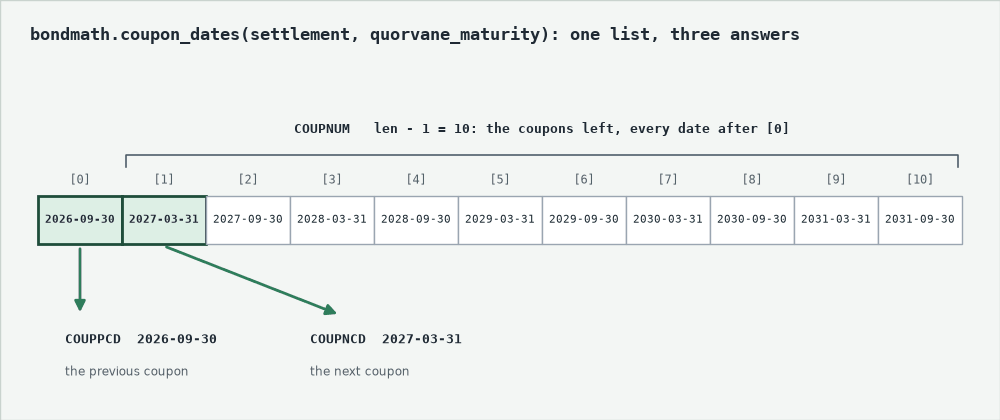

One list answers all three questions.

### Quorvane on 30 November

Q. What are Quorvane's previous coupon, next coupon, and coupons left?

In [26]:
importlib.reload(bondmath)
quorvane_dates = bondmath.coupon_dates(settlement, quorvane_maturity)
print('Previous', quorvane_dates[0], ' next', quorvane_dates[1],
      ' coupons left', len(quorvane_dates) - 1)

Previous 2026-09-30  next 2027-03-31  coupons left 10


Quorvane was issued on 30 September and has paid nothing yet, but interest accrues from that date.

### Four Bonds Against Excel

Q. Do all four bonds tie to Excel's `COUPPCD`, `COUPNCD`, and `COUPNUM`?

In [27]:
# the file's rows for the four bonds settled 30 November 2026, in the table's order
week2 = reference[reference['group'] == 'week2']
excel = week2.loc[bonds['cusip']]
all_dates = [bondmath.coupon_dates(settlement, m) for m in bonds['maturity_date']]
# isoformat() writes a date as year-month-day text, as the file holds it
schedule = pd.DataFrame({'ticker': bonds['ticker'],
                         'previous': [d[0].isoformat() for d in all_dates],
                         'next': [d[1].isoformat() for d in all_dates],
                         'left': [len(d) - 1 for d in all_dates]})
schedule

,ticker,previous,next,left
0,QVNE,2026-09-30,2027-03-31,10
1,DNMR,2026-09-30,2027-03-31,14
2,PLWK,2026-09-30,2027-03-31,6
3,HLVF,2026-09-30,2027-03-31,20


In [28]:
# .to_numpy() drops the row labels, so the two columns line up by position
assert (schedule['previous'].to_numpy() == excel['couppcd'].to_numpy()).all()
assert (schedule['next'].to_numpy() == excel['coupncd'].to_numpy()).all()
assert (schedule['left'].to_numpy() == excel['coupnum'].to_numpy()).all()
print('All four tie to COUPPCD, COUPNCD, and COUPNUM')

All four tie to COUPPCD, COUPNCD, and COUPNUM


**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Previous coupon</td><td align="left"><code>quorvane_dates[0]</code></td><td align="left"><code>=COUPPCD(DATE(2026,11,30),DATE(2031,9,30),2,0)</code></td><td align="left">2026-09-30</td></tr>
<tr><td align="left">Next coupon</td><td align="left"><code>quorvane_dates[1]</code></td><td align="left"><code>=COUPNCD(DATE(2026,11,30),DATE(2031,9,30),2,0)</code></td><td align="left">2027-03-31</td></tr>
<tr><td align="left">Coupons left</td><td align="left"><code>len(quorvane_dates) - 1</code></td><td align="left"><code>=COUPNUM(DATE(2026,11,30),DATE(2031,9,30),2,0)</code></td><td align="left">10</td></tr>
</table>
<br clear="left">

The last argument, the basis, is the day count (0 is 30/360), and it does not move the dates.

### Coupons Still to Come

Q. Draw each bond's coupons still to come, with settlement marked.

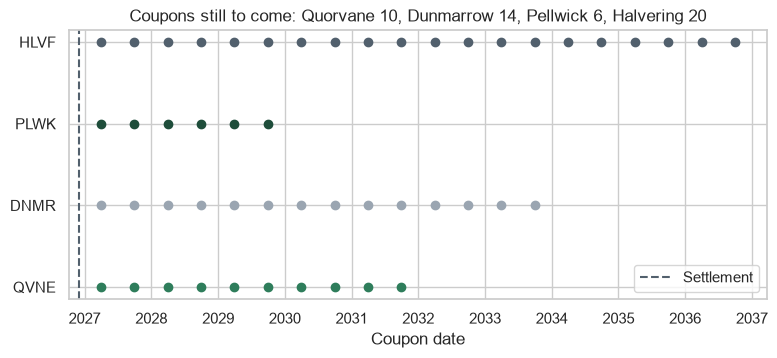

In [29]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for row, d in enumerate(all_dates):
    # d[1:] leaves out the previous coupon; one row of dots per bond
    ax.plot(d[1:], [row] * len(d[1:]), marker='o', linestyle='none')
ax.axvline(settlement, color='#52606D', linestyle='--', label='Settlement')
ax.set_yticks(range(4), bonds['ticker'])
ax.set_title('Coupons still to come: Quorvane 10, Dunmarrow 14, Pellwick 6, Halvering 20')
ax.set_xlabel('Coupon date')
ax.legend()
plt.show()

### How Long Is Each Period?

Q. How many actual days is each of Quorvane's coupon periods?

In [30]:
# zip pairs each date with the next, as in notebook 05's falling-price test
lengths = [(later - earlier).days
           for earlier, later in zip(quorvane_dates, quorvane_dates[1:])]
print(lengths)

[182, 183, 183, 183, 182, 183, 182, 183, 182, 183]


182 or 183 actual days; 30/360 counts every one as 180, notebook 07's count.

### After Maturity

Q. What does `coupon_dates` do with a settlement after maturity?

In [31]:
bondmath.coupon_dates(date(2031, 10, 1), quorvane_maturity)

ValueError: settlement 2031-10-01 must be before maturity 2031-09-30

A matured bond has no next coupon, and a silent answer would be wrong.

### The Test

The test runs `coupon_dates` on all 306 rows of Excel's file, 50 edge cases among them.
`row["case_id"]` after each `assert` names a failing row.

Q. Add the test and run every test.

In [32]:
%%writefile -a test_bondmath.py


def test_coupon_dates_match_excel():
    for row in REFERENCE:
        settlement, maturity = date.fromisoformat(row["settlement"]), date.fromisoformat(row["maturity"])
        dates = bondmath.coupon_dates(settlement, maturity, int(row["frequency"]))
        # [0] is COUPPCD, [1] is COUPNCD, and the number of dates after [0] is COUPNUM
        assert dates[0] == date.fromisoformat(row["couppcd"]), row["case_id"]
        assert dates[1] == date.fromisoformat(row["coupncd"]), row["case_id"]
        assert len(dates) - 1 == int(row["coupnum"]), row["case_id"]

Appending to test_bondmath.py


In [33]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...............                                                          [100%]
15 passed in 0.50s



**The note's first ask: 30 September and 31 March for all four, and 10, 14, 6, and 20 coupons left, as Excel says on all 306 rows.**

## 6.7 Keep the Cache Out of Git

### What Changed

Q. What has changed in the work folder since notebook 05's commit?

In [34]:
# M: changed since the last commit; ??: untracked, as in notebook 04
!git -C "{work}" status --short
!git -C "{work}" diff --stat

 M bondmath.py
 M test_bondmath.py
?? __pycache__/
 bondmath.py      | 58 ++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 test_bondmath.py | 23 ++++++++++++++++++++++
 2 files changed, 81 insertions(+)


`__pycache__/` is where Python keeps compiled copies of the module and the tests.
Python rebuilds it at will, so it never belongs in the record.
A `.gitignore` file lists names Git should not offer to track, one to a line; a name ending in `/` is a folder.

### Write `.gitignore`

In [35]:
%%writefile .gitignore
# folders Python and pytest make: never part of the record
__pycache__/
.pytest_cache/

Writing .gitignore


### Status Again, Then Commit

Q. Is the cache gone? Then commit the module, the tests, and the `.gitignore` together.

In [36]:
!git -C "{work}" status --short
subject = 'Notebook 06: add_months, coupon_dates, and a .gitignore'
body = 'Week 2 settles between coupons; every later function needs these dates.'
!git -C "{work}" add bondmath.py test_bondmath.py .gitignore
!git -C "{work}" commit -q -m "{subject}" -m "{body}"
!git -C "{work}" log --oneline --decorate

 M bondmath.py
 M test_bondmath.py
?? .gitignore
7df5427 (HEAD -> main) Notebook 06: add_months, coupon_dates, and a .gitignore
f8c61d7 (tag: week1) Notebook 05: tests of par pricing and of price against yield
f6fc975 Notebook 04: yield_from_price
3f57cac Notebook 03: convert_yield
408a678 Notebook 02: cash_flows and price_from_yield
d029474 Notebook 01: future_value and present_value


The cache is gone from the status; `.gitignore` itself goes in the record, so every copy ignores the same names.

**Git records the work, not what Python rebuilds.**

## 6.8 The Holdings' Coupon Calendar

### Text to Dates

Q. How many of the 200 holdings mature on a month end?

In [37]:
holdings = pd.read_csv('holdings.csv')
# text to dates, as in Course 1's Combining and Loading Part 2
# .dt.is_month_end is True on a month's last day
maturities = pd.to_datetime(holdings['maturity'])
print(len(holdings), 'bonds,', maturities.dt.is_month_end.sum(), 'maturing on a month end')

200 bonds, 0 maturing on a month end


None, so the month-end rule never touches this file.

### Next Coupon for 200 Bonds

Q. When is each holding's next coupon after the file's date?

In [38]:
# .dt.date gives back plain date values, the kind bondmath takes
as_of = pd.to_datetime(holdings['as_of_date']).dt.date
holdings['next_coupon'] = [bondmath.coupon_dates(a, m)[1]
                           for a, m in zip(as_of, maturities.dt.date)]
holdings[['cusip', 'as_of_date', 'maturity', 'next_coupon']].head(3)

,cusip,as_of_date,maturity,next_coupon
0,99080CAE8,2026-09-30,2032-06-18,2026-12-18
1,99049XAE2,2026-09-30,2029-04-17,2026-10-17
2,99039NAC0,2026-09-30,2030-06-03,2026-12-03


### Holdings by Month of Next Coupon

Q. How many bonds pay their next coupon in each month?

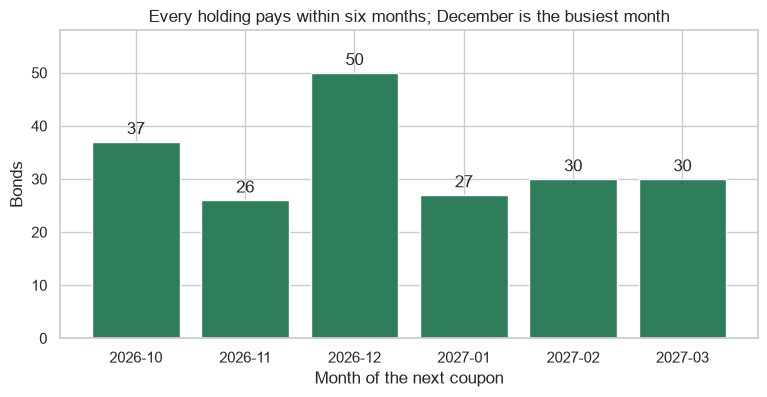

In [39]:
# %Y-%m: the year and month as text, the format codes of Course 1's EDA notebook
holdings['coupon_month'] = pd.to_datetime(holdings['next_coupon']).dt.strftime('%Y-%m')
by_month = holdings['coupon_month'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(by_month.index, by_month.values)
ax.bar_label(bars, padding=3)
ax.set_ylim(0, 58)
ax.set_title('Every holding pays within six months; December is the busiest month')
ax.set_xlabel('Month of the next coupon')
ax.set_ylabel('Bonds')
plt.show()

### Coupon Cash Before Year End

Q. Which bonds pay a coupon by 31 December 2026, and how many dollars is that on the par held?

In [40]:
due = holdings[holdings['next_coupon'] <= date(2026, 12, 31)].copy()
# half a year's coupon in dollars: par held x coupon in percent / 100 / 2
due['coupon_dollars'] = due['par_held'] * due['coupon'] / 100 / 2
print(len(due), 'bonds pay', f"{due['coupon_dollars'].sum():,.2f}", 'dollars by year end')
(due.groupby('coupon_month').agg(bonds=('cusip', 'count'), dollars=('coupon_dollars', 'sum'))
    .style.format({'dollars': '{:,.2f}'}).bar(subset=['dollars'], color='#DDEFE5'))

113 bonds pay 8,540,781.25 dollars by year end


,bonds,dollars
coupon_month,,
2026-10,37,"2,930,468.75"
2026-11,26,"1,833,906.25"
2026-12,50,"3,776,406.25"


This describes the file's cash calendar; it says nothing about any bond's value.

### Two Systems Disagree

Q. Which benchmark bonds mature on a month end, and where does the first one's previous coupon fall, by Excel's rule and with the day kept?

In [41]:
benchmark = pd.read_csv('benchmark.csv')
pair = benchmark[pd.to_datetime(benchmark['maturity']).dt.is_month_end]
print(pair[['cusip', 'as_of_date', 'maturity', 'accrued']])
dates = bondmath.coupon_dates(date(2026, 9, 30), date(2038, 2, 28))
# the previous coupon is len - 1 steps of 6 months back from maturity
print('99018SAA8, month-end rule:', dates[0])
print('99018SAA8, day kept:', bondmath.add_months(date(2038, 2, 28), -6 * (len(dates) - 1)))

         cusip  as_of_date    maturity  accrued
96   99018SAA8  2026-09-30  2038-02-28    0.456
706  99128YAE4  2026-09-30  2035-02-28    0.844
99018SAA8, month-end rule: 2026-08-31
99018SAA8, day kept: 2026-08-28


![Bond 99018SAA8 matures on 28 February 2038, the last day of February. Two schedules back from it: Excel's month-end rule puts the previous coupon on 31 August 2026; the data file kept the 28th, so 28 August 2026. The as-of date, 30 September 2026, sits after both, three days apart. The bond's own documents decide which is right](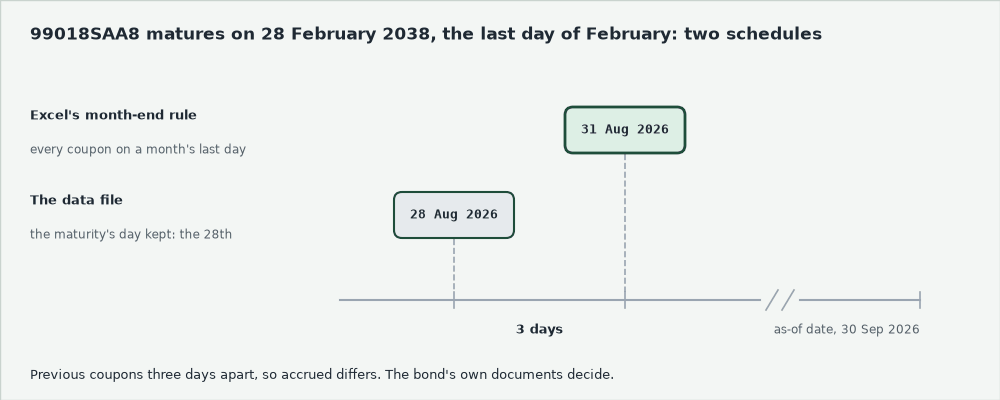)

28 February 2038 is a month end, so Excel's rule says 31 August.
The program that wrote the file kept the 28th: its accrued, 0.456, counts from 28 August.
Both are conventions: for a real bond, its documents decide.

**113 bonds pay 8,540,781.25 dollars of coupon by year end; the two February bonds sit three days apart by convention.**

## Bring It Home

Copy the work folder's three files into your own folder, then test and commit there.
In a PowerShell terminal in VS Code, with the course's `.venv` active, use the work folder name your setup cell printed:

```powershell
Set-Location "$HOME\projects\my_bondmath"
$work = "$env:TEMP\pfi_course2_06_k4w7q2xr"
Copy-Item "$work\bondmath.py", "$work\test_bondmath.py", "$work\.gitignore" .
python -m pytest -q
git status --short
git add bondmath.py test_bondmath.py .gitignore
git commit -m "Notebook 06: add_months, coupon_dates, and a .gitignore"
```

The copy replaces your files, so anything of your own goes into the work folder first.
In Colab, download the files instead.
The work folder stays in your temp folder until you delete it.

## You Can Now

By the end of this notebook, you can:

* Make, compare, and subtract dates, and say what Excel's date serials count.
* Move a date by months with `add_months` or `EDATE`.
* Count coupon dates back from maturity, and say why stepping drifts.
* Apply the month-end rule, with `EOMONTH` in Excel.
* Find the previous coupon, next coupon, and coupons left with `coupon_dates`, tied to Excel.
* Hand a pandas date column to the module with `.dt.date`.
* Keep the cache out of Git with a `.gitignore`.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The second set of week 1 bonds, settled on 30 November 2026; all four mature on 30 September.
Replace each `...` with your code, then run the check cell under it.
Run the next two cells first.

In [42]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [43]:
exercise_bonds = pd.DataFrame({
    'ticker': ['OSTV', 'TRNW', 'OSMC', 'CLDB'],
    'issuer': ['Ostrevale Telecom', 'Tarnwick Utilities', 'Osmere Chemicals', 'Calderby Retail'],
    'maturity': ['2030-09-30', '2028-09-30', '2032-09-30', '2034-09-30'],
})
exercise_bonds['maturity_date'] = [date.fromisoformat(t) for t in exercise_bonds['maturity']]
settlement = date(2026, 11, 30)
exercise_bonds

,ticker,issuer,maturity,maturity_date
0,OSTV,Ostrevale Telecom,2030-09-30,2030-09-30
1,TRNW,Tarnwick Utilities,2028-09-30,2028-09-30
2,OSMC,Osmere Chemicals,2032-09-30,2032-09-30
3,CLDB,Calderby Retail,2034-09-30,2034-09-30


### Exercise 1

Q. Find each bond's previous coupon, next coupon, and coupons left with `bondmath.coupon_dates`. Store Calderby's next coupon, a `date`, in **ex1_next**, and the coupons left across all four in **ex1_total**.

In [44]:
ex1_next = ...
ex1_total = ...

In [45]:
check('Exercise 1 Calderby next coupon', ex1_next, date(2027, 3, 31))
check('Exercise 1 coupons left, all four', ex1_total, 40)

Exercise 1 Calderby next coupon: not attempted yet
Exercise 1 coupons left, all four: not attempted yet


### Exercise 2

Q. Find the length in actual days of each of Calderby's coupon periods. Store the shortest in **ex2_shortest**, the longest in **ex2_longest**, and the number of 183-day periods in **ex2_count_183**.

In [46]:
ex2_shortest = ...
ex2_longest = ...
ex2_count_183 = ...

In [47]:
check('Exercise 2 shortest period', ex2_shortest, 182)
check('Exercise 2 longest period', ex2_longest, 183)
check('Exercise 2 periods of 183 days', ex2_count_183, 10)

Exercise 2 shortest period: not attempted yet
Exercise 2 longest period: not attempted yet
Exercise 2 periods of 183 days: not attempted yet


### Exercise 3

Q. Add `coupons_remaining(settlement, maturity, frequency=2)` to your module, Excel's `COUPNUM`, built on `coupon_dates`, docstring first. Test it in `test_coupons_remaining_matches_excel_coupnum` with one case by hand and every `REFERENCE` row's `coupnum`. Run 6.6's pytest cell again, reload, and store Tarnwick's coupons left in **ex3_tarnwick**.

In [48]:
%%writefile -a bondmath.py


# Exercise 3: write coupons_remaining(settlement, maturity, frequency=2) below this line

Appending to bondmath.py


In [49]:
%%writefile -a test_bondmath.py


# Exercise 3: write test_coupons_remaining_matches_excel_coupnum() below this line

Appending to test_bondmath.py


In [50]:
# reload the module, then call your function
ex3_tarnwick = ...

In [51]:
check('Exercise 3 Tarnwick coupons left', ex3_tarnwick, 4)

Exercise 3 Tarnwick coupons left: not attempted yet


### Exercise 4: AI check

You gave an AI assistant `coupon_dates`' docstring as the request: the docstring is the prompt.
This came back, written for this course in the style of an assistant's answer.

In [52]:
# written for this course in the style of an AI assistant's answer.
# It runs, and it contains one bug.
def assistant_coupon_dates(settlement, maturity, frequency=2):
    """The previous coupon date, then every coupon date left through maturity.

    Units: dates. Convention: coupon dates are counted back from maturity in steps of
    12 / frequency months, each one computed from maturity directly, so a 31st never drifts
    to the 28th. If maturity is the last day of its month, every coupon date is the last day
    of its month (Excel's rule). The previous coupon date is the last one on or before
    settlement. So [0] is Excel's COUPPCD, [1] is COUPNCD, and len - 1 is COUPNUM.
    """
    if frequency not in (1, 2, 4):
        raise ValueError(f'frequency must be 1, 2, or 4, not {frequency}')
    if settlement >= maturity:
        raise ValueError(f'settlement {settlement} must be before maturity {maturity}')
    step_months = 12 // frequency
    month_end = maturity.day == calendar.monthrange(maturity.year, maturity.month)[1]
    dates = [maturity]
    # step back one period at a time until a date is on or before settlement
    while dates[-1] > settlement:
        coupon_date = bondmath.add_months(dates[-1], -step_months)
        if month_end:
            last_day = calendar.monthrange(coupon_date.year, coupon_date.month)[1]
            coupon_date = date(coupon_date.year, coupon_date.month, last_day)
        dates.append(coupon_date)
    dates.reverse()
    return dates

Q. What should Quorvane's next coupon be on 30 November 2026? Section 6.6 has it. Run the function.

In [53]:
print('Quorvane next coupon:', assistant_coupon_dates(settlement, date(2031, 9, 30))[1])

Quorvane next coupon: 2027-03-31


Q. Test it against every row of Excel's file before you trust it.

In [54]:
rows = pd.read_csv('bondmath_excel_reference.csv')
for case, s, m, f, previous, coming in zip(rows['case_id'], rows['settlement'], rows['maturity'],
                                           rows['frequency'], rows['couppcd'], rows['coupncd']):
    dates = assistant_coupon_dates(date.fromisoformat(s), date.fromisoformat(m), f)
    assert dates[0].isoformat() == previous, f'{case}: previous {dates[0]}, COUPPCD {previous}'
    assert dates[1].isoformat() == coming, f'{case}: next {dates[1]}, COUPNCD {coming}'
print(f'All {len(rows)} rows match COUPPCD and COUPNCD')

AssertionError: edge_mat_29_aug: previous 2026-08-28, COUPPCD 2026-08-29

Q. Fix the convention the code broke and run the test again. Store the fixed function's previous coupon on 30 November 2026 for maturities of 29 and 30 August 2031 in **ex4_aug29_previous** and **ex4_aug30_previous**.

In [55]:
ex4_aug29_previous = ...
ex4_aug30_previous = ...

In [56]:
check('Exercise 4 previous coupon, 29 August maturity', ex4_aug29_previous, date(2026, 8, 29))
check('Exercise 4 previous coupon, 30 August maturity', ex4_aug30_previous, date(2026, 8, 30))

Exercise 4 previous coupon, 29 August maturity: not attempted yet
Exercise 4 previous coupon, 30 August maturity: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Previous coupon</td><td align="left">30 September 2026, all four</td></tr>
<tr><td align="left">Next coupon</td><td align="left">31 March 2027, all four, by the month-end rule</td></tr>
<tr><td align="left">Coupons left</td><td align="left">Quorvane 10, Dunmarrow 14, Pellwick 6, Halvering 20</td></tr>
<tr><td align="left">The date logic, with tests</td><td align="left"><code>add_months</code> and <code>coupon_dates</code>, 15 tests, all 306 rows of <code>COUPPCD</code>, <code>COUPNCD</code>, and <code>COUPNUM</code></td></tr>
<tr><td align="left">Coupon cash by year end</td><td align="left">113 bonds, 8,540,781.25 dollars on the par held</td></tr>
<tr><td align="left">The two benchmark bonds</td><td align="left">The file kept the 28th; Excel's month-end rule says 31 August</td></tr>
</table>
<br clear="left">

Be proud: your schedule is right to the day, and you can prove it on every row Excel gave you.

Next, Day Counts and Accrued Interest (notebook 07) counts the days between these dates.